# Gradient dominance experiments

Empirical check of Theorem 4.3 (gradient dominance) from Gatmiry et al. (2024) for **looped** linear transformers.

Assumptions from the paper that are enforced here:
- Population covariance $\Sigma^* = I$ (the `normal` data mode, `U = D = None`).
- $u = 0$: the top-left $d \times d$ block of $P$ is zeroed and frozen, so only $Q$ (the preconditioner $A$) is trained.

Theorem 4.3: if
$$\mathcal{L}(A, 0) \ge \frac{16 d^{3/2} L d 4^L}{\sqrt{n}},$$
then
$$\|\nabla_A \mathcal{L}(A, 0)\|^2 \ge \frac{L - \frac{1}{2}}{4 d^{(L-1)/(2L-1)}} \mathcal{L}(A, 0)^{(2L-1)/L}.$$

Here $n$ is the context length `N` and $L$ is the number of loops.

The last section repeats the experiment with a non-identity population covariance $\Sigma^* = U D^2 U^\top$. Theorem 4.3 assumes $\Sigma^* = I$, so that section goes beyond what the paper proves.

In [16]:
# Imports and setup

import torch
from matplotlib import pyplot as plt
import os
import time
import numpy as np

from experiments_helper import build_transformer, step
from linear_transformer import generate_data, in_context_loss

np.set_printoptions(precision=2, suppress=True)
torch.set_printoptions(precision=2)

log_dir = 'log'
cur_dir = log_dir
os.makedirs(cur_dir, exist_ok=True)

In [17]:
# Problem parameters (defined in experiments_helper.py; edit them there so the
# helper functions see the same values)

from experiments_helper import (
    device, lr, clip_r, normal_data_mode, B, n_head, var,
    max_iters, stride,
)

# Revised parameters
alg = 'sgd'

print(f'Running on device: {device}.')

Running on device: cuda.


## Theorem 4.3 helpers

In [18]:
def get_loss_lower_bound(d, L, n):
    # Loss threshold from Theorem 4.3: 16 d^{3/2} L d 4^L / sqrt(n).
    return 16 * d ** 1.5 * L * d * 4 ** L / np.sqrt(n)


def is_loss_lower_bound_valid(loss, loss_lower_bound):
    # True when the loss is large enough for Theorem 4.3 to apply.
    return bool(loss >= loss_lower_bound)


def get_squared_norm(gradients):
    # Left side of Theorem 4.3: ||grad_A L(A, 0)||^2 (squared Frobenius norm).
    return gradients.detach().pow(2).sum().item()


def get_squared_norm_lower_bound(d, L, loss):
    # Right side of Theorem 4.3: (L - 1/2) / (4 d^{(L-1)/(2L-1)}) * loss^{(2L-1)/L}.
    return (L - 0.5) / (4 * d ** ((L - 1) / (2 * L - 1))) * loss ** ((2 * L - 1) / L)


def is_gradient_dominance_valid(squared_norm, squared_norm_lower_bound):
    # True when the gradient dominance inequality holds.
    return bool(squared_norm >= squared_norm_lower_bound)

## Training with gradient dominance tracking

The training loop mirrors `run_experiment_suite` in `experiments_helper.py`, but records the loss and the gradient of $Q$ (i.e. $A$) at every iteration, before clipping and before the optimizer step. $P$ is kept at zero so that $u = 0$.

In [19]:
def run_gradient_dominance_experiment(seeds, loop_counts, context_lengths=[],
                                      data_mode=normal_data_mode, iters=max_iters,
                                      dim=None, U=None, D=None, covariance_label='identity'):
    # Train looped transformers and evaluate Theorem 4.3 at every iteration.
    # Returns {(seed, L, N): dict of per-iteration numpy arrays}.
    # dim defaults to the global d. U, D give covariates covariance U D^2 U^T
    # (see generate_data); leave them as None for identity covariance.
    if dim is None:
        dim = d
    results = {}
    for seed in seeds:
        for L in loop_counts:
            for context_length in context_lengths:
                key = (seed, L, context_length)
                print(f'Run: seed={seed}, L={L}, N={context_length}')

                torch.manual_seed(seed)
                model = build_transformer('looped', L, n_head, dim, var).to(device)
                model.zero_p()  # u = 0 assumption: P stays zero for the whole run

                if alg == 'sgd':
                    optimizer = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=0)
                elif alg == 'adam':
                    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, betas=(0.9, 0.9), weight_decay=0)
                else:
                    raise ValueError(f'Unsupported optimizer: {alg}')

                loss_lower_bound = get_loss_lower_bound(dim, L, context_length)
                record = {name: np.full(iters, np.nan) for name in (
                    'loss', 'squared_norm', 'squared_norm_lower_bound')}
                record['loss_bound_valid'] = np.zeros(iters, dtype=bool)
                record['gradient_dominance_valid'] = np.zeros(iters, dtype=bool)
                record['loss_lower_bound'] = loss_lower_bound
                record['d'] = dim
                record['covariance'] = covariance_label

                np.random.seed(seed)
                torch.manual_seed(seed)
                for t in range(iters):
                    start = time.time()
                    Z, y = generate_data(data_mode, context_length, dim, B, U=U, D=D)
                    loss = in_context_loss(model, Z.to(device), y.to(device))
                    loss.backward()

                    # Only train A (= Q); drop the P gradient to keep u = 0.
                    model.allparam.grad[:, :, 0].zero_()
                    A_grad = model.allparam.grad[0, 0, 1]

                    loss_value = loss.item()
                    squared_norm = get_squared_norm(A_grad)
                    squared_norm_lower_bound = get_squared_norm_lower_bound(dim, L, loss_value)

                    record['loss'][t] = loss_value
                    record['squared_norm'][t] = squared_norm
                    record['squared_norm_lower_bound'][t] = squared_norm_lower_bound
                    record['loss_bound_valid'][t] = is_loss_lower_bound_valid(loss_value, loss_lower_bound)
                    record['gradient_dominance_valid'][t] = is_gradient_dominance_valid(
                        squared_norm, squared_norm_lower_bound)

                    # We do not perform gradient clipping in this experiment to make it consistent with the paper
                    grad_norm = step(model.allparam, optimizer, clip_r=None)
                    optimizer.zero_grad()
                    model.zero_p()

                    if t % 100 == 0 or t < 5:
                        print(f'iter {t} | Loss: {loss_value:.4g} | ||grad_A||^2: {squared_norm:.4g} '
                              f'| RHS: {squared_norm_lower_bound:.4g} | time: {time.time() - start:.3f} '
                              f'| gradnorm: {grad_norm:.4g}')

                results[key] = record
    return results

In [20]:
def print_gradient_dominance_summary(results):
    # How often the loss precondition holds, and how often gradient dominance
    # holds (overall, and on iterations where the precondition holds).
    for key, record in results.items():
        seed, L, context_length = key
        loss_ok = record['loss_bound_valid']
        gd_ok = record['gradient_dominance_valid']
        conditional = gd_ok[loss_ok].mean() if loss_ok.any() else float('nan')
        print(f'[{record.get("covariance", "identity")}] seed={seed}, L={L}, N={context_length}: '
              f'loss bound={record["loss_lower_bound"]:.2f}, '
              f'max loss={np.nanmax(record["loss"]):.4g}, '
              f'loss precondition holds {loss_ok.mean():.1%}, '
              f'gradient dominance holds {gd_ok.mean():.1%} overall, '
              f'{conditional:.1%} when precondition holds')


def plot_gradient_dominance(results, plot_iters=None,
                            fig_dir=os.path.join('figures', 'gradient_dominance')):
    # Left: ||grad_A L||^2, the Theorem 4.3 lower bound, and their ratio.
    # Right: training loss against the Theorem 4.3 loss threshold.
    # plot_iters=None plots every iteration; otherwise only the first plot_iters.
    os.makedirs(fig_dir, exist_ok=True)
    for key, record in results.items():
        seed, L, context_length = key
        record = {name: value[:plot_iters] if isinstance(value, np.ndarray) else value
                  for name, value in record.items()}
        covariance = record.get('covariance', 'identity')
        run_d = record.get('d', d)
        steps = np.arange(len(record['loss']))
        fig, axs = plt.subplots(1, 2, figsize=(12, 4))

        axs[0].plot(steps, record['squared_norm'], lw=1, label=r'$\|\nabla_A \mathcal{L}\|^2$')
        axs[0].plot(steps, record['squared_norm_lower_bound'], lw=1, label='Theorem 4.3 lower bound')
        # Ratio of the two sides; gradient dominance holds wherever it is >= 1.
        axs[0].plot(steps, record['squared_norm'] / record['squared_norm_lower_bound'], lw=1,
                    alpha=0.7, label=r'$\|\nabla_A \mathcal{L}\|^2$ / lower bound')
        axs[0].axhline(1, color='black', linestyle=':', lw=1, label='ratio = 1')
        axs[0].set_yscale('log')
        axs[0].set_xlabel('Iteration')
        axs[0].set_title('Gradient dominance')
        axs[0].legend()
        axs[0].grid(True, which='both', alpha=0.2)

        axs[1].plot(steps, record['loss'], lw=1, label='training loss')
        axs[1].axhline(record['loss_lower_bound'], color='tab:red', linestyle='--',
                       label='Theorem 4.3 loss threshold')
        axs[1].set_yscale('log')
        axs[1].set_xlabel('Iteration')
        axs[1].set_title('Loss precondition')
        axs[1].legend()
        axs[1].grid(True, which='both', alpha=0.2)

        fig.suptitle(f'Looped, L={L}, N={context_length}, d={run_d}, seed={seed}, covariance={covariance}')
        fig.tight_layout()
        cov_suffix = '' if covariance == 'identity' else f'_{covariance}'
        fig.savefig(os.path.join(
            fig_dir, f'gradient_dominance_L{L}_N{context_length}_seed{seed}{cov_suffix}.pdf'), dpi=600)
        plt.show()

In [21]:
gd_seeds = [1]
gd_loop_counts = [1]
gd_context_lengths = [100]
d = 2

# Size of the loss threshold for the settings used below. The theorem only
# applies when the training loss is at least this large.
for L in gd_loop_counts:
    for n in gd_context_lengths:
        print(f'L={L}, n={n}: loss lower bound = {get_loss_lower_bound(d, L, n):.2f}')

L=1, n=100: loss lower bound = 36.20


In [22]:
gd_results = run_gradient_dominance_experiment(gd_seeds, gd_loop_counts, gd_context_lengths)
torch.save({'gd_results': gd_results}, os.path.join(cur_dir, f'gradient_dominance_{d}.pth'))

Run: seed=1, L=1, N=100
iter 0 | Loss: 2.035 | ||grad_A||^2: 8.35 | RHS: 0.2544 | time: 0.018 | gradnorm: 2.89
iter 1 | Loss: 2.031 | ||grad_A||^2: 8.285 | RHS: 0.2539 | time: 0.013 | gradnorm: 2.878
iter 2 | Loss: 2.012 | ||grad_A||^2: 8.177 | RHS: 0.2515 | time: 0.008 | gradnorm: 2.859
iter 3 | Loss: 2.03 | ||grad_A||^2: 8.493 | RHS: 0.2537 | time: 0.008 | gradnorm: 2.914
iter 4 | Loss: 1.917 | ||grad_A||^2: 7.688 | RHS: 0.2396 | time: 0.009 | gradnorm: 2.773
iter 100 | Loss: 0.07923 | ||grad_A||^2: 0.07631 | RHS: 0.009904 | time: 0.008 | gradnorm: 0.2762
iter 200 | Loss: 0.0666 | ||grad_A||^2: 0.001336 | RHS: 0.008325 | time: 0.008 | gradnorm: 0.03655
iter 300 | Loss: 0.05486 | ||grad_A||^2: 0.0008177 | RHS: 0.006857 | time: 0.008 | gradnorm: 0.0286
iter 400 | Loss: 0.05768 | ||grad_A||^2: 0.0001445 | RHS: 0.00721 | time: 0.008 | gradnorm: 0.01202
iter 500 | Loss: 0.05801 | ||grad_A||^2: 0.002381 | RHS: 0.007251 | time: 0.008 | gradnorm: 0.04879
iter 600 | Loss: 0.05205 | ||grad_A||

## Results

In [23]:
print_gradient_dominance_summary(gd_results)

[identity] seed=1, L=1, N=100: loss bound=36.20, max loss=2.035, loss precondition holds 0.0%, gradient dominance holds 1.4% overall, nan% when precondition holds


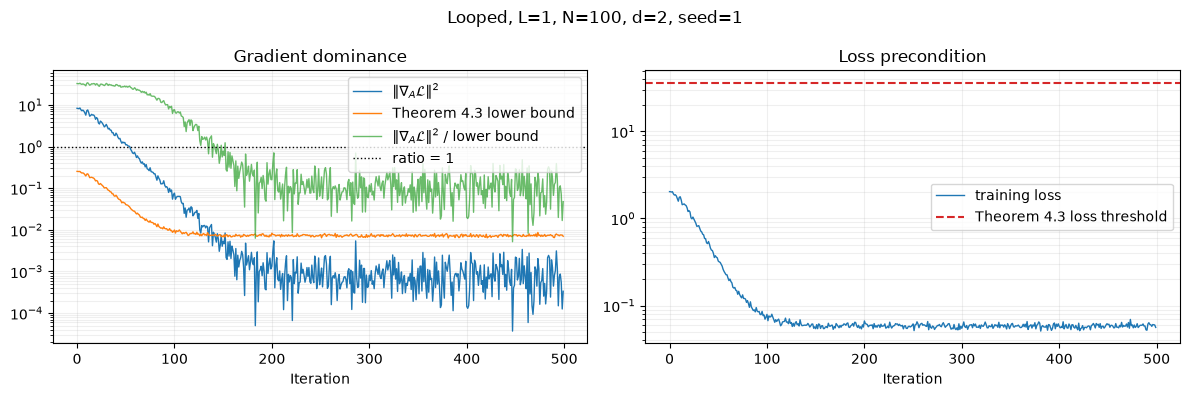

In [ ]:
# ||grad_A L||^2 against the Theorem 4.3 lower bound over training.
plot_iters = 10000  # only plot the first plot_iters iterations
plot_gradient_dominance(gd_results, plot_iters=plot_iters)

## Non-identity population covariance

Same experiment with covariates $x \sim \mathcal{N}(0, \Sigma^*)$ where $\Sigma^* = U D^2 U^\top$, using the rotation $U$ and scaling $D$ from `oos_regular_experiments.ipynb`. `generate_data` also draws $w^* \sim \mathcal{N}(0, \Sigma^{*-1})$ in this case, matching the paper's setup. Theorem 4.3 is only proven for $\Sigma^* = I$.

In [ ]:
# Covariance configuration from oos_regular_experiments.ipynb (defined for d = 5).
cov_d = 5
torch.manual_seed(1234)
rotation_seed_matrix = (2 * torch.rand(cov_d, cov_d, device=device)) - 1
U_cov = torch.linalg.svd(rotation_seed_matrix, full_matrices=True).U
D_cov = torch.diag(torch.tensor([1, 1, 0.5, 0.25, 1], device=device))

cov_seeds = gd_seeds
cov_loop_counts = gd_loop_counts
cov_context_lengths = gd_context_lengths

Sigma_cov = U_cov @ D_cov @ D_cov @ U_cov.T
print('Population covariance eigenvalues:', torch.linalg.eigvalsh(Sigma_cov).cpu().numpy())
for L in cov_loop_counts:
    for n in cov_context_lengths:
        print(f'L={L}, n={n}: loss lower bound = {get_loss_lower_bound(cov_d, L, n):.2f}')

RuntimeError: mm: mat1 and mat2 shapes cannot be multiplied (6x6 and 5x5)

In [25]:
cov_results = run_gradient_dominance_experiment(
    cov_seeds, cov_loop_counts, cov_context_lengths,
    dim=cov_d, U=U_cov, D=D_cov, covariance_label='rotated',
)
torch.save({'gd_results': cov_results}, os.path.join(cur_dir, f'gradient_dominance_rotated_{cov_d}.pth'))

Run: seed=1, L=1, N=100
iter 0 | Loss: 4.845 | ||grad_A||^2: 10.9 | RHS: 0.6056 | time: 0.061 | gradnorm: 3.302
iter 1 | Loss: 4.941 | ||grad_A||^2: 11.21 | RHS: 0.6177 | time: 0.015 | gradnorm: 3.348
iter 2 | Loss: 4.882 | ||grad_A||^2: 11.48 | RHS: 0.6102 | time: 0.012 | gradnorm: 3.388
iter 3 | Loss: 4.792 | ||grad_A||^2: 11.38 | RHS: 0.599 | time: 0.012 | gradnorm: 3.374
iter 4 | Loss: 4.63 | ||grad_A||^2: 10.2 | RHS: 0.5787 | time: 0.012 | gradnorm: 3.194
iter 100 | Loss: 1.878 | ||grad_A||^2: 0.2579 | RHS: 0.2347 | time: 0.012 | gradnorm: 0.5079
iter 200 | Loss: 1.828 | ||grad_A||^2: 0.1881 | RHS: 0.2285 | time: 0.012 | gradnorm: 0.4337
iter 300 | Loss: 1.581 | ||grad_A||^2: 0.1609 | RHS: 0.1976 | time: 0.012 | gradnorm: 0.4011
iter 400 | Loss: 1.452 | ||grad_A||^2: 0.116 | RHS: 0.1815 | time: 0.012 | gradnorm: 0.3406
iter 500 | Loss: 1.367 | ||grad_A||^2: 0.0879 | RHS: 0.1708 | time: 0.011 | gradnorm: 0.2965
iter 600 | Loss: 1.358 | ||grad_A||^2: 0.07888 | RHS: 0.1697 | time: 0.

[rotated] seed=1, L=1, N=100: loss bound=357.77, max loss=5.103, loss precondition holds 0.0%, gradient dominance holds 1.4% overall, nan% when precondition holds


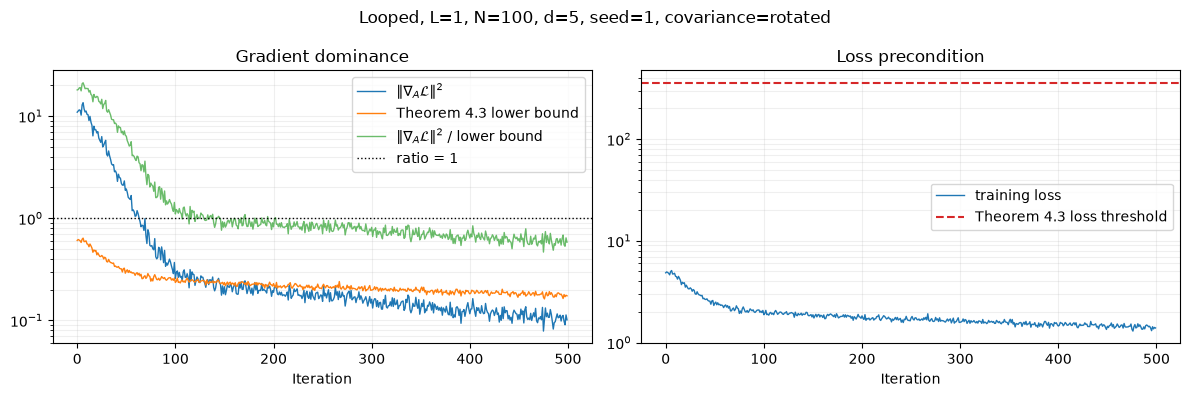

In [26]:
print_gradient_dominance_summary(cov_results)
plot_gradient_dominance(cov_results, plot_iters=plot_iters)